## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH =  "/content/drive/MyDrive/Lab04/dataset/processed.cleveland.data"


## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [ ]:
# TODO: Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
df = pd.read_csv(DATA_PATH,header=None,na_values="?")
print(df.head())
print(df.columns)
df.rename(columns={13: "target"}, inplace=True)

df.columns

     0    1    2      3      4    5    6      7    8    9    10   11   12  13
0  63.0  1.0  1.0  145.0  233.0  1.0  2.0  150.0  0.0  2.3  3.0  0.0  6.0   0
1  67.0  1.0  4.0  160.0  286.0  0.0  2.0  108.0  1.0  1.5  2.0  3.0  3.0   2
2  67.0  1.0  4.0  120.0  229.0  0.0  2.0  129.0  1.0  2.6  2.0  2.0  7.0   1
3  37.0  1.0  3.0  130.0  250.0  0.0  0.0  187.0  0.0  3.5  3.0  0.0  3.0   0
4  41.0  0.0  2.0  130.0  204.0  0.0  2.0  172.0  0.0  1.4  1.0  0.0  3.0   0
Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], dtype='int64')


Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 'target'], dtype='object')

## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there? 303 samples and 14 features
- What are the column names and data types?0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13 0     float64
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
13      int64
- What do the first 5 rows look like?
     0    1    2      3      4    5    6      7    8    9    10   11   12  13
0  63.0  1.0  1.0  145.0  233.0  1.0  2.0  150.0  0.0  2.3  3.0  0.0  6.0   0
1  67.0  1.0  4.0  160.0  286.0  0.0  2.0  108.0  1.0  1.5  2.0  3.0  3.0   2
2  67.0  1.0  4.0  120.0  229.0  0.0  2.0  129.0  1.0  2.6  2.0  2.0  7.0   1
3  37.0  1.0  3.0  130.0  250.0  0.0  0.0  187.0  0.0  3.5  3.0  0.0  3.0   0
4  41.0  0.0  2.0  130.0  204.0  0.0  2.0  172.0  0.0  1.4  1.0  0.0  3.0   0

- What are the descriptive statistics (`describe()`)?
mean std and quantiles of each feature
- What is the target variable and what values does it take?
array([0, 2, 1, 3, 4])


In [ ]:
# TODO: Inspect shape, columns, dtypes, head(), and describe()
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.head())
print(df.describe())
df["target"].unique()

(303, 14)
Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 'target'], dtype='object')
0         float64
1         float64
2         float64
3         float64
4         float64
5         float64
6         float64
7         float64
8         float64
9         float64
10        float64
11        float64
12        float64
target      int64
dtype: object
      0    1    2      3      4    5    6      7    8    9   10   11   12  \
0  63.0  1.0  1.0  145.0  233.0  1.0  2.0  150.0  0.0  2.3  3.0  0.0  6.0   
1  67.0  1.0  4.0  160.0  286.0  0.0  2.0  108.0  1.0  1.5  2.0  3.0  3.0   
2  67.0  1.0  4.0  120.0  229.0  0.0  2.0  129.0  1.0  2.6  2.0  2.0  7.0   
3  37.0  1.0  3.0  130.0  250.0  0.0  0.0  187.0  0.0  3.5  3.0  0.0  3.0   
4  41.0  0.0  2.0  130.0  204.0  0.0  2.0  172.0  0.0  1.4  1.0  0.0  3.0   

   target  
0       0  
1       2  
2       1  
3       0  
4       0  
                0           1           2           3           4           5  \
count  303.000000  303.000000  3

array([0, 2, 1, 3, 4])

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
target
0    54.125413
1    18.151815
2    11.881188
3    11.551155
4     4.290429
Name: proportion, dtype: float64


<Axes: xlabel='target'>

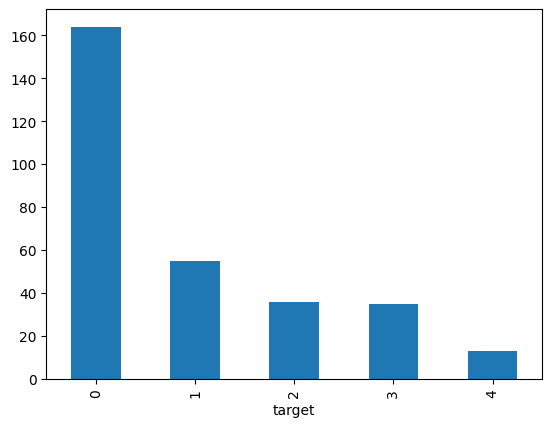

In [ ]:
# TODO: Count target classes, compute percentages, and plot the distribution
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True)*100)
df["target"].value_counts().plot(kind='bar')


## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).
Column 12 has 2 and 11 has 4 missing values / Nan
we drop there rows

In [ ]:
# TODO: Check for missing values, duplicates, dtypes, and unique values per column
print(df.isnull().sum())
print("________________________________________________________")
print(df.duplicated().sum())
print("________________________________________________________")
print(df.dtypes)
print("________________________________________________________")
print(df.nunique())

0         0
1         0
2         0
3         0
4         0
5         0
6         0
7         0
8         0
9         0
10        0
11        4
12        2
target    0
dtype: int64
________________________________________________________
0
________________________________________________________
0         float64
1         float64
2         float64
3         float64
4         float64
5         float64
6         float64
7         float64
8         float64
9         float64
10        float64
11        float64
12        float64
target      int64
dtype: object
________________________________________________________
0          41
1           2
2           4
3          50
4         152
5           2
6           3
7          91
8           2
9          40
10          3
11          4
12          3
target      5
dtype: int64


In [ ]:
df.dropna(inplace=True)
print(df.isnull().sum())
df.head()

0         0
1         0
2         0
3         0
4         0
5         0
6         0
7         0
8         0
9         0
10        0
11        0
12        0
target    0
dtype: int64


,0,1,2,3,4,5,6,7,8,9,10,11,12,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

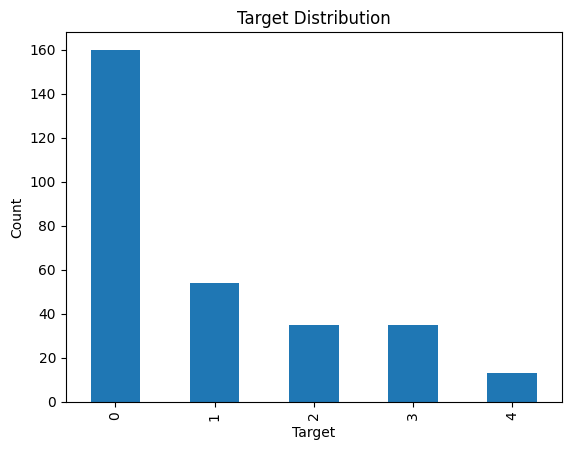

In [ ]:
# TODO: Create the required visualizations

df["target"].value_counts().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()


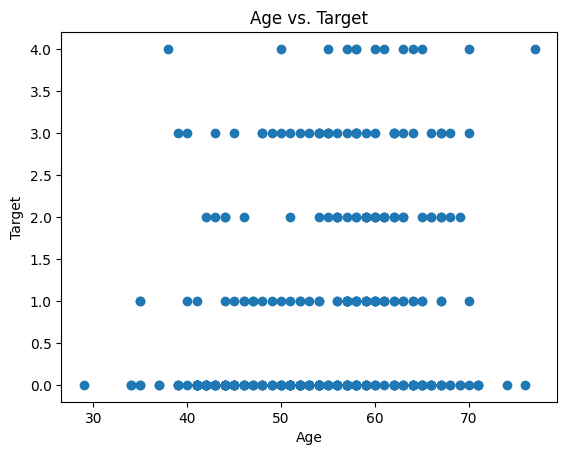

In [ ]:
plt.scatter(df[0], df["target"])
plt.title("Age vs. Target")
plt.xlabel("Age")
plt.ylabel("Target")
plt.show()

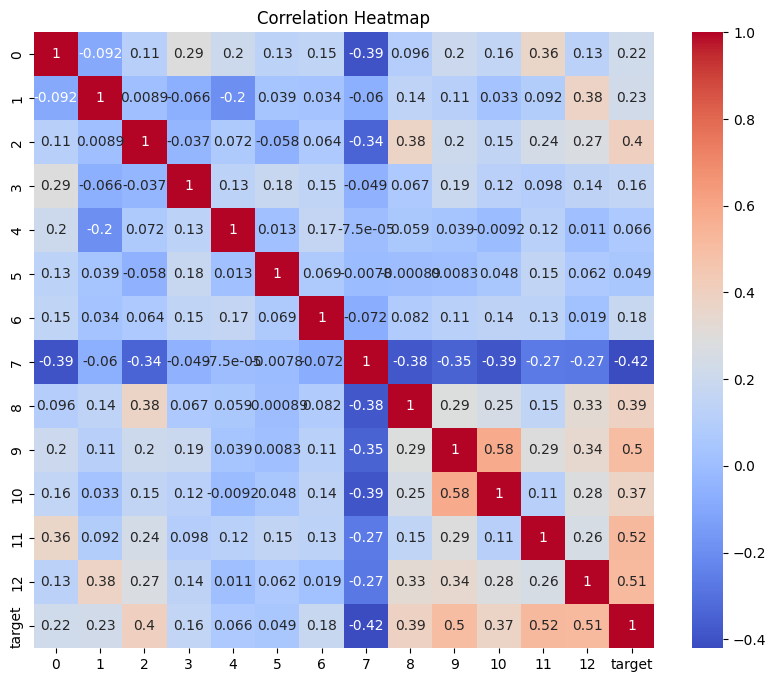

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop("target", axis=1)
y = df["target"]

numerical_features = [0, 3, 4, 7, 9]
categorical_features = [1, 2, 5, 6, 8, 10, 11, 12]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)



print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training dtype" , type(X_train))

Training shape: (207, 28)
Testing shape: (90, 28)
Training dtype <class 'numpy.ndarray'>


In [ ]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.long)

In [ ]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |     13    |     ReLU       |
| Hidden 1 |      32   |       Relu     |
| Hidden 2 |     32    |      Relu      |
| Hidden 3 |    32     |       Relu     |
| Hidden 4 |   32       |      Relu      |
| Output   |   5      |      sigmoid      |

*(Delete rows you don't use if your design has fewer than 4 hidden layers.)*

## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |       13      |       32        |      (13 × 32) + 32       |     448       |
| Hidden 2 |    32         |      32         |    (32 × 32) + 32         |     1056       |
| Hidden 3 |     32        |        32       |      (32x32)+32       |      1056      |
| Hidden 4 |     32        |      32         |     (32x 32)+32        |     1056       |
| Output   |     32        |         5      |      (32 x 5)+5       |    165        |
| **Total**|   |       448 + 1056+1056+1056+1056+165         |      =4837         |            |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [ ]:



class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # Input → hidden
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),

            # Hidden layer
            nn.Linear(hidden_dim, 16),
            nn.ReLU(),

            # Hidden layer
            nn.Linear(16, 8),
            nn.ReLU(),

            # Hidden layer
            nn.Linear(8, 12),
            nn.ReLU(),

            # Hidden layer
            nn.Linear(12, 12),
            nn.ReLU(),

            # Output layer
            nn.Linear(12, output_dim),

        )

    def forward(self, x):
        return self.model(x)


model = MyModel(
    input_dim=28,
    hidden_dim=32,
    output_dim=5
)

print(model)


MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=12, bias=True)
    (7): ReLU()
    (8): Linear(in_features=12, out_features=12, bias=True)
    (9): ReLU()
    (10): Linear(in_features=12, out_features=5, bias=True)
  )
)


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [ ]:
# TODO: Choose an appropriate loss function
loss_function = nn.CrossEntropyLoss()


## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [ ]:
# TODO: Choose an optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 1000


## Cell 14 — Compile the Model

In [ ]:
history = {
    "train_loss": []
}

for epoch in range(num_epochs):

    model.train()
    train_loss = 0

    for X, y in train_loader:

        optimizer.zero_grad()

        outputs = model(X) # forward prop

        loss = loss_function(outputs, y)

        loss.backward() # back prop

        optimizer.step() # update step

        train_loss += loss.item()

    train_loss /= len(train_loader)

    history["train_loss"].append(train_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {train_loss:.4f}")

Epoch [1/1000] Loss: 1.5630
Epoch [2/1000] Loss: 1.5500
Epoch [3/1000] Loss: 1.5320
Epoch [4/1000] Loss: 1.5123
Epoch [5/1000] Loss: 1.4938
Epoch [6/1000] Loss: 1.4730
Epoch [7/1000] Loss: 1.4602
Epoch [8/1000] Loss: 1.4437
Epoch [9/1000] Loss: 1.4320
Epoch [10/1000] Loss: 1.3984
Epoch [11/1000] Loss: 1.3910
Epoch [12/1000] Loss: 1.3715
Epoch [13/1000] Loss: 1.3172
Epoch [14/1000] Loss: 1.2574
Epoch [15/1000] Loss: 1.2098
Epoch [16/1000] Loss: 1.1502
Epoch [17/1000] Loss: 1.0899
Epoch [18/1000] Loss: 1.0347
Epoch [19/1000] Loss: 1.0245
Epoch [20/1000] Loss: 1.0133
Epoch [21/1000] Loss: 0.9669
Epoch [22/1000] Loss: 0.9390
Epoch [23/1000] Loss: 0.9301
Epoch [24/1000] Loss: 0.9437
Epoch [25/1000] Loss: 0.8920
Epoch [26/1000] Loss: 0.9257
Epoch [27/1000] Loss: 0.9266
Epoch [28/1000] Loss: 0.9023
Epoch [29/1000] Loss: 0.8861
Epoch [30/1000] Loss: 0.8681
Epoch [31/1000] Loss: 0.8688
Epoch [32/1000] Loss: 0.8242
Epoch [33/1000] Loss: 0.8397
Epoch [34/1000] Loss: 0.8218
Epoch [35/1000] Loss: 0

## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

Text(0, 0.5, 'Loss')

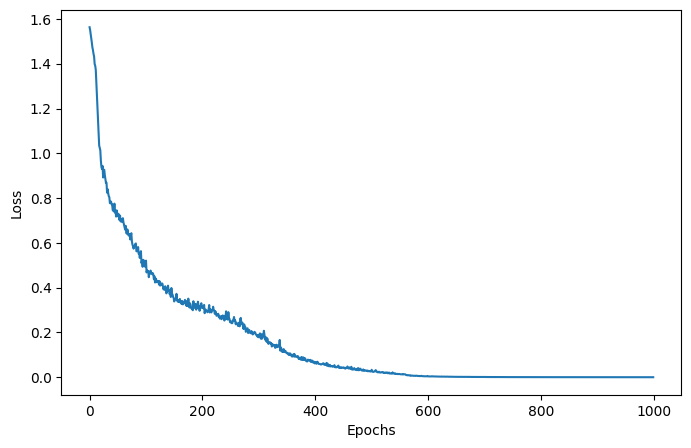

In [ ]:
# TODO: Plot training and validation loss from `history`

plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"])
plt.xlabel("Epochs")
plt.ylabel("Loss")


## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        predictions = torch.argmax(outputs, dim=1)

        y_pred.extend(predictions.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Accuracy : 0.4556
Precision: 0.4633
Recall   : 0.4556
F1-score : 0.4588


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
# TODO: Create, train, and evaluate an AdaBoostClassifier
ada_model = AdaBoostClassifier(n_estimators=100)

# TODO: Fit on training data
ada_model.fit(X_train, y_train)

# TODO: Predict on test data
y_pred_ada = ada_model.predict(X_test)

# TODO: Calculate and display accuracy, precision, recall, and F1-score
accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(
    y_test,
    y_pred_ada,
    average="weighted",
    zero_division=0,)
recall_ada = recall_score(
    y_test,
    y_pred_ada,
    average="weighted",
    zero_division=0,)
f1_ada = f1_score(
    y_test,
    y_pred_ada,
    average="weighted",
    zero_division=0,)
print(f"Accuracy : {accuracy_ada:.4f}")
print(f"Precision: {precision_ada:.4f}")
print(f"Recall   : {recall_ada:.4f}")
print(f"F1-score : {f1_ada:.4f}")


Accuracy : 0.5889
Precision: 0.5720
Recall   : 0.5889
F1-score : 0.5787


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |       0.5000    |    0.4771       |     0.5000  |     0.4846   |
| AdaBoost       |       0.5889   |    0.5720      |     0.5889    |     0.5787     |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance


The Neural Network shows signs of overfitting. Its training loss decreased substantially from around 1.6233 to 0.0080, indicating that the model learned the training data very well. However, its test accuracy remained only 50.00%, suggesting that this strong performance on the training data did not translate equally well to unseen data. This large difference between the very low training loss and the relatively modest test performance indicates that the model may be fitting the training data too closely. Since no validation set was used, overfitting cannot be confirmed directly, but the results provide evidence of possible overfitting. Techniques such as dropout, reducing the network size, or other regularization methods could help improve generalization.
The difference in performance between the Neural Network and AdaBoost can be due to their different learning approaches, as the Neural Network learns complex nonlinear relationships through multiple layers while AdaBoost combines multiple weak decision-tree learners. Since the dataset is relatively small, the Neural Network may also have learned the training data too closely, as indicated by its low training loss of 0.1905 compared with its test accuracy of 58.89%. Feature normalization may have affected the Neural Network more because neural networks are sensitive to feature scales, while AdaBoost is generally less affected by scaling. Differences in model complexity and hyperparameter choices may also have contributed to the difference in their performance.



## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
target class is imbalnced with 0's dominating the field
2. The important preprocessing steps you applied
missing values were removed and the features were scaled
3. Your neural network architecture and design choices
4 hidden layers each with same hidden_dims and the final output layer of 32 , 5 with 5 outputs since 5 classes
4. Neural network evaluation results
Accuracy : 0.5000
Precision: 0.4771
Recall   : 0.5000
F1-score : 0.4846
5. AdaBoost evaluation results
Accuracy : 0.5889
Precision: 0.5720
Recall   : 0.5889
F1-score : 0.5787
6. Comparison between the two models
Ada performed better tho it doesnt require feature scaling and NN overfitted extremely hard
7. Possible improvements for future work
Add regularizaton and drop out for NN and take a larger data set for imbalance classes